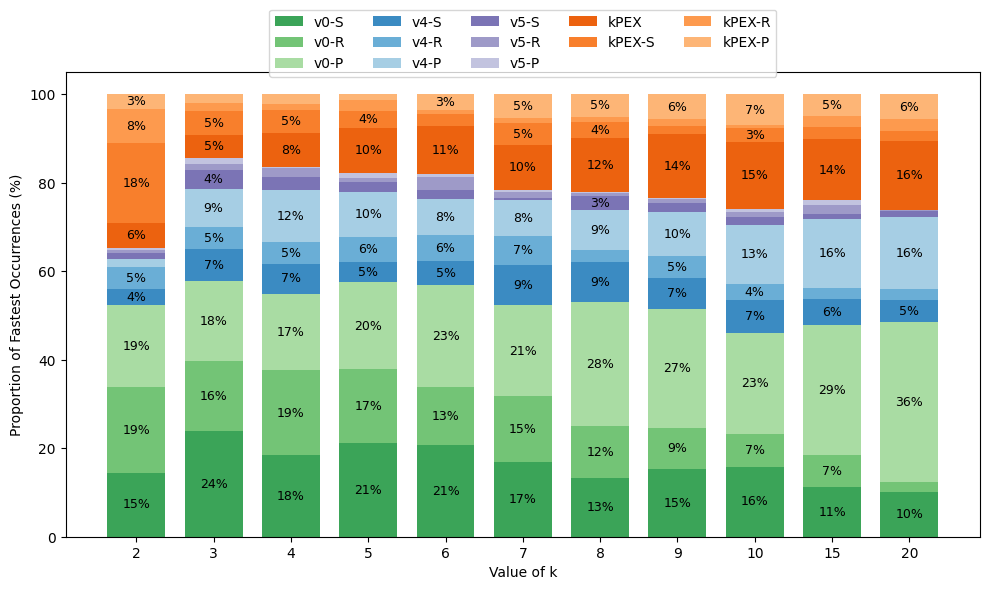

In [3]:
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# -------------------------------------------------
# Load data
# -------------------------------------------------
file_path = "results-filtered-dataset.csv"
df = pd.read_csv(file_path)

# -------------------------------------------------
# Define groups (clean, 4 groups)
# -------------------------------------------------
groups = [
    ["v0-S", "v0-R", "v0-P"],          # group 2
    ["v4-S", "v4-R", "v4-P"],          # group 1
    ["v5-S", "v5-R", "v5-P"],          # group 2
    ["kPEX", "kPEX-S","kPEX-R", "kPEX-P"]    
]

all_algos = sum(groups, [])

# -------------------------------------------------
# Preprocess
# -------------------------------------------------
df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)

k_values = [2,3,4,5,6,7,8,9,10,15,20]

# store percentages
results = {algo: [] for algo in all_algos}

# -------------------------------------------------
# Compute winners
# -------------------------------------------------
for k in k_values:

    df_k = df[df["k"] == k]

    if len(df_k) == 0:
        for algo in all_algos:
            results[algo].append(0)
        continue

    winners = df_k[all_algos].idxmin(axis=1)

    win_counts = winners.value_counts()
    total = len(df_k)

    for algo in all_algos:
        wins = win_counts.get(algo, 0)
        percent = (wins / total) * 100
        results[algo].append(percent)

# convert to dataframe
res_df = pd.DataFrame(results, index=k_values)

# -------------------------------------------------
# Colors (one colormap per group)
# -------------------------------------------------
cmaps = [plt.cm.Greens, plt.cm.Blues, plt.cm.Purples, plt.cm.Oranges]

colors = {}
for group, cmap in zip(groups, cmaps):
    shades = cmap(np.linspace(0.65, 0.35, len(group)))
    for algo, shade in zip(group, shades):
        colors[algo] = shade

# -------------------------------------------------
# Stacked bar plot
# -------------------------------------------------
x = np.arange(len(k_values))

fig, ax = plt.subplots(figsize=(10,6))

bottom = np.zeros(len(k_values))
black_font_algos = {"UMKP-S"}  # optional

for algo in all_algos:
    vals = res_df[algo].values

    ax.bar(
        x,
        vals,
        bottom=bottom,
        label=algo,
        width=0.75,
        color=colors[algo]
    )

    # annotate
    for i, v in enumerate(vals):
        if v > 3:
            text_color = "white" if algo in black_font_algos else "black"
            ax.text(
                x[i],
                bottom[i] + v/2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                fontsize=9,
                color=text_color
            )

    bottom += vals

# -------------------------------------------------
# Final styling
# -------------------------------------------------
ax.set_xlabel("Value of k")
ax.set_ylabel("Proportion of Fastest Occurrences (%)")

ax.set_xticks(x)
ax.set_xticklabels(k_values)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=5
)

plt.tight_layout()
# plt.show()